In [397]:
# Import data handling libraries
import pandas as pd   # for loading and manipulating data
import numpy as np    # for numerical operations

# Import visualization libraries
import matplotlib.pyplot as plt   # for plotting graphs
import seaborn as sns             # for statistical plots

# Import machine learning tools from scikit-learn
from sklearn.model_selection import train_test_split   # to split data into train/test sets
from sklearn.preprocessing import StandardScaler       # to scale feature values
from sklearn.linear_model import LogisticRegression    # for classification model I use
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score)   # to create evaluation metrics

In [398]:
BCdata = pd.read_csv('/content/Breast_cancer_data.csv')     #To upload breast cancer data and save as BCdata

In [399]:
BCdata.info()     #To view dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [400]:
BCdata.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [401]:
BCdata.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [402]:
# Drop irrelevant coloumns present in the raw dataset - the coloumn No.32
BCdata.drop(columns=["id", "Unnamed: 32"], errors="ignore", inplace=True)

Breast Cancer Type:
  Benign (0): 357
  Malignant (1): 212


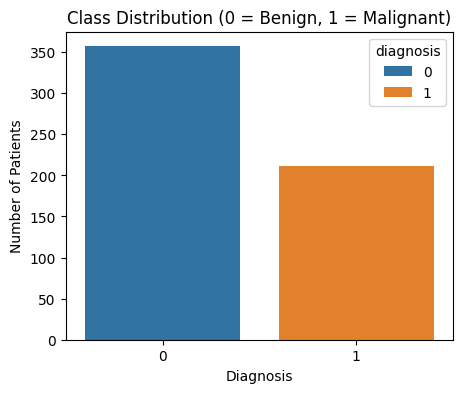

In [403]:
# Convert diagnosis coloumn to binary numeric labels
# Malignant (M) - 1 (cancer present) & Benign (B) - 0 (no cancer)
BCdata["diagnosis"] = BCdata["diagnosis"].map({"M": 1, "B": 0})

# To display No.of Malignant and Benign cases
print("Breast Cancer Type:")
for label, count in BCdata["diagnosis"].value_counts().items():
    status = "Malignant (1)" if label == 1 else "Benign (0)"
    print(f"  {status}: {count}")

# Plot to show how many malignant vs benign cases
plt.figure(figsize=(5,4))
sns.countplot(x="diagnosis", data=BCdata, hue="diagnosis")
plt.title("Class Distribution (0 = Benign, 1 = Malignant)")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.show()

In [404]:
# Separate features (X) from the target label (y) from whole dataset
X = BCdata.drop(columns=['diagnosis'])       # X have all columns(input features) except diagnosis
y = BCdata['diagnosis']                      # y is diagnosis column that is what we want to predict

# Split whole dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature scaling
scaler = StandardScaler()                   # create a scaler object
X_train = scaler.fit_transform(X_train)     # learn scaling parameters from training data
X_test = scaler.transform(X_test)           # apply the same scaling to test data

# Display No.of training and testing samples
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [405]:
# Initialize the Logistic Regression model
log_reg_model = LogisticRegression(max_iter=5000, random_state=42)

# Train the model using the training data
log_reg_model.fit(X_train, y_train)

# Predict class labels (Benign - 0 or Malignant - 1) for the unseen test data
y_pred = log_reg_model.predict(X_test)

# Predict probabilities for the ROC curve
y_pred_proba = log_reg_model.predict_proba(X_test)[:, 1]   # probability of Malignant

# Display first 10 actual vs predicted values for checking
results = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10]})
print(results)

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          1
5       0          0
6       1          1
7       0          0
8       0          0
9       0          0


Model Accuracy: 96.49%
Classification Report:
               precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



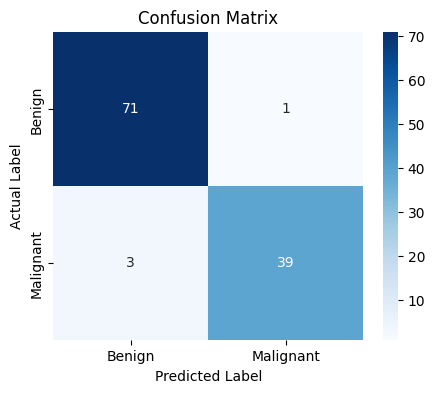

In [406]:
# Calculate overall accuracy of correct predictions
accuracy = accuracy_score(y_test, y_pred)

# Prepare full classification report
class_report=classification_report(y_test, y_pred, target_names=["Benign", "Malignant"])

# Display Model accuracy and Classification report
print(f"Model Accuracy: {accuracy*100:.2f}%")
print("Classification Report:\n", class_report)

# Plot confusion matrix: shows correct vs incorrect predictions per class
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


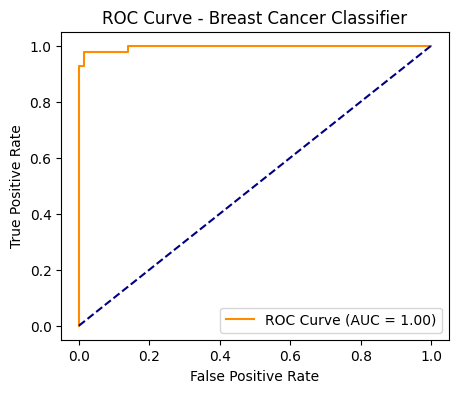

In [407]:
# Compute the ROC curve points and the Area Under Curve (AUC) score
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

# Plot the ROC curve
plt.figure(figsize=(5,4))
plt.plot(fpr, tpr, color="darkorange", label=f"ROC Curve (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")   # diagonal = random guess baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Breast Cancer Classifier")
plt.legend(loc="lower right")
plt.show()

In [408]:
# Testing the model using a new unseen record from dataset
sample_scaled = X_test[0:1]                                      #Already scaled sample
prediction = log_reg_model.predict(sample_scaled)[0]             # get prediction from trained model
probability = log_reg_model.predict_proba(sample_scaled)[0][1]   # get confidence score

# Assigning label(class) for prediction
diagnosis_label = "Malignant" if prediction == 1 else "Benign"

# Display Predicted results, Confidence score and Actual results
print(f"Predicted Diagnosis: {diagnosis_label}")
print(f"Confidence (probability of malignancy): {probability*100:.2f}%")
print(f"Actual Diagnosis: {'Malignant' if y_test.iloc[0]==1 else 'Benign'}")

Predicted Diagnosis: Benign
Confidence (probability of malignancy): 0.04%
Actual Diagnosis: Benign


In [409]:
# Saving and loading the model and scaler for real world applications
import joblib
print(joblib.__version__)

model = log_reg_model
joblib.dump(model, 'Breast_Cancer_Detection_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

model = joblib.load('Breast_Cancer_Detection_model.pkl')
scale = joblib.load('scaler.pkl')

1.5.3
